# 04. 이상 추세 및 일탈 파악 통계 기법 검증
2026-11-25 | 생산 완료 후 수율 감시 PoC. 기존 RCA 결과를 변경하지 않는다.
- 공통 시간 경계: Code 13/17/23 종료시각의 60% 위치 (기존 분할 재사용).
- 그룹 A(유효 기준 배치 40 이상): 가상 규격 및 SPC 후보, B(10–39): 잠정 규격, C: 보류.
- Q10 원값, 0.5%p 내림 하한을 구분하고 기존 가상 USL을 재사용한다. 승인 규격 아님.
- 실제 수율 공개 시각, 정상 상태, 승인 규격과 일탈 라벨은 미확인. 통계 신호는 조사 지원용이다.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data'/'Laboratory.csv').is_file()), None)
assert ROOT is not None, 'yield_experiment 프로젝트에서 실행하세요.'
LAB=ROOT/'data'/'Laboratory.csv'
AUDIT=ROOT/'results/revision_20261125/01_batch_audit_v2/batch_duration_audit.csv'
SPEC=ROOT/'results/spec_all_products_q10/all_product_specifications_q10.csv'
OUT=ROOT/'results/revision_20261125/04_statistical_detection'
OUT.mkdir(parents=True,exist_ok=True)
for p in [LAB,AUDIT,SPEC]: assert p.is_file(), p
KEY=['code','batch']; FOCUS=[13,17,23]; Q=.10
R=['r1_low','r1_high','r2_low','r2_high','r3_low','r3_high','mr_high']
print('Notebook 04 v1',OUT)

Notebook 04 v1 /Users/park-inki/Desktop/SKALA-yield-model/yield_experiment/results/revision_20261125/04_statistical_detection


## 1. 데이터 품질 및 시간순 분할
수율 범위 밖의 값은 원본을 보존하고 통계 검토 대상에서 제외한다. 100% 초과가 오류라고 확정하지 않는다. 기존 가상 규격을 적용한 기록은 별도로 대조한다. 기준 배치는 종료 < cutoff, 평가 배치는 시작 >= cutoff. 경계 배치는 평가하지 않되 완료 순서상 후속 배치의 이력으로 사용한다. 생산 종료가 수율 공개 시각의 대리값이라는 가정.

In [2]:
lab=pd.read_csv(LAB,sep=';',usecols=KEY+['tbl_yield'])
log=pd.read_csv(AUDIT,usecols=KEY+['start_ts','end_ts','campaign','duration_min'])
old=pd.read_csv(SPEC).set_index('code')
assert old.index.is_unique
for x in [lab,log]:
    assert not x[KEY].isna().any().any() and not x.duplicated(KEY).any()
assert lab[KEY].merge(log[KEY],on=KEY,how='outer',indicator=True)['_merge'].eq('both').all()
df=lab.merge(log,on=KEY,validate='one_to_one')
for col in ['start_ts','end_ts']: df[col]=pd.to_datetime(df[col],format='mixed',errors='raise')
assert df[['start_ts','end_ts']].notna().all().all() and df.end_ts.ge(df.start_ts).all()
df['tbl_yield']=pd.to_numeric(df.tbl_yield,errors='coerce')
df['valid_yield']=df.tbl_yield.between(0,100)
df['y']=df.tbl_yield.where(df.valid_yield)
df.loc[~df.valid_yield].to_csv(OUT/'yield_quality_review.csv',index=False)
f=df[df.code.isin(FOCUS)]
cut=f.end_ts.sort_values().iloc[int(len(f)*.60)]
df['phase']=np.select([df.end_ts.lt(cut),df.start_ts.ge(cut)],['train','test'],default='boundary')
df=df.sort_values(['code','end_ts','batch']).reset_index(drop=True)
df['end_tie']=df.duplicated(['code','end_ts'],keep=False)
print('Batches:',len(df),'Products:',df.code.nunique(),'Cutoff:',cut,'Quality review:',(~df.valid_yield).sum())
print('Focus split:'); display(pd.crosstab(df[df.code.isin(FOCUS)].code,df[df.code.isin(FOCUS)].phase))

Batches: 1005 Products: 25 Cutoff: 2020-10-19 02:16:00 Quality review: 1
Focus split:


phase,boundary,test,train
code,,,
13,1,60,70
17,0,88,119
23,0,61,126


## 2. 기준 산출 및 탐지 규칙
가상 LSL = Q10을 0.5%p 단위로 내림. USL은 기존 PoC 설정 파일의 usl_candidate를 재사용하며 승인 규격으로 간주하지 않는다. 기준 기간 유효 수율만 사용하여 평균, 표준편차, MR 평균을 산출한다. I 관리한계 = 평균 ± 3 × MR평균/1.128, MR 상한 = 3.267 × MR평균. 관리한계는 0~100으로 자르지 않는다. 동시 종료 배치와 결측은 순서 의존 규칙의 연속성을 끊는다. I Rule 1과 규격 비교는 개별 유효값으로 수행한다. 기준 기간 자체의 신호는 적합에 사용한 데이터의 기술적 점검이며 독립 검증이 아니다.

In [3]:
def get_limits(g,min_spc=40):
    y=g.y; n=int(y.count()); mr=y.mask(g.end_tie).diff().abs().dropna()
    cl=y.mean(); sd=y.std(); mrbar=mr.mean(); sigma=mrbar/1.128
    q10=y.quantile(Q) if n>=10 else np.nan
    lsl=np.floor(q10*2)/2 if pd.notna(q10) else np.nan
    code=int(g.code.iloc[0]) if len(g) else None
    usl=float(old.loc[code,'usl_candidate']) if code in old.index and n>=10 else np.nan
    spec_ready=bool(n>=10 and np.isfinite(lsl) and np.isfinite(usl) and lsl<=usl)
    imr=bool(n>=min_spc and np.isfinite(mrbar) and mrbar>0)
    return dict(valid_ref_n=n,ref_rows=len(g),group='A' if n>=40 else 'B' if n>=10 else 'C',q10=q10,lsl=lsl,usl=usl,spec_ready=spec_ready,imr_ready=imr,cl=cl,sd=sd,mrbar=mrbar,mr_ref_n=len(mr),lcl=cl-3*sigma if imr else np.nan,ucl=cl+3*sigma if imr else np.nan,mr_ucl=3.267*mrbar if imr else np.nan)

def flags(g,p):
    y=g.y.reset_index(drop=True); order=y.mask(g.end_tie.reset_index(drop=True)); d=order.diff()
    f=pd.DataFrame({'r1_low':y.lt(p['lcl']),'r1_high':y.gt(p['ucl']),
      'r2_low':order.lt(p['cl']).rolling(9,min_periods=9).sum().eq(9),'r2_high':order.gt(p['cl']).rolling(9,min_periods=9).sum().eq(9),
      'r3_low':d.lt(0).rolling(5,min_periods=5).sum().eq(5),'r3_high':d.gt(0).rolling(5,min_periods=5).sum().eq(5),
      'mr_high':d.abs().gt(p['mr_ucl']),'mr':d.abs(), 'q10_low':y.lt(p['q10']), 'spec_low':y.lt(p['lsl']), 'spec_high':y.gt(p['usl'])})
    if not p['imr_ready']: f[R]=False
    if not p['spec_ready']: f[['spec_low','spec_high','q10_low']]=False
    f['spec_any']=f.spec_low|f.spec_high; f['spc_any']=f[R].any(axis=1)
    f['spc_lower']=f[['r1_low','r2_low','r3_low']].any(axis=1)
    f['z_score']=(y-p['cl'])/p['sd'] if p['valid_ref_n']>=10 and pd.notna(p['sd']) and p['sd']>0 else np.nan
    return f

def score(g,p):
    a=g.reset_index(drop=True).copy(); a=pd.concat([a,flags(a,p)],axis=1)
    for k in ['group','spec_ready','imr_ready','cl','lcl','ucl','mr_ucl','q10','lsl','usl']: a[k]=p[k]
    a['spc_status']=np.select([~a.valid_yield,~a.imr_ready,a.spc_any],['quality_review','insufficient_reference','signal'],default='no_signal')
    a['spec_status']=np.select([~a.valid_yield,~a.spec_ready,a.group.eq('B')&a.spec_any,a.group.eq('B'),a.spec_any],['quality_review','insufficient_reference','provisional_signal','provisional_no_signal','poc_signal'],default='poc_no_signal')
    a['fired_rules']=a[R].apply(lambda r: ','.join(r.index[r]),axis=1)
    return a

p=dict(cl=95.,lcl=92.,ucl=98.,sd=1.,mr_ucl=3.,q10=93.,lsl=93.,usl=100.,imr_ready=True,spec_ready=True,valid_ref_n=40)
def toy(vals,ties=None): return pd.DataFrame({'y':vals,'end_tie':ties if ties is not None else [False]*len(vals)})
assert flags(toy([90]),p).r1_low.iloc[-1]
assert not flags(toy([92]),p).r1_low.iloc[-1]
assert flags(toy([94]*9),p).r2_low.iloc[-1]
assert flags(toy([96]*9),p).r2_high.iloc[-1]
assert not flags(toy([94]*4+[np.nan]+[94]*4),p).r2_low.iloc[-1]
assert flags(toy([99,98,97,96,95,94]),p).r3_low.iloc[-1]
assert flags(toy([94,95,96,97,98,99]),p).r3_high.iloc[-1]
assert not flags(toy([99,98,98,96,95,94]),p).r3_low.iloc[-1]
assert not flags(toy([99,98,np.nan,96,95,94]),p).r3_low.iloc[-1]
assert not flags(toy([99,98,97,96,95,94],[False,True,True,False,False,False]),p).r3_low.iloc[-1]
assert flags(toy([99,94]),p).mr_high.iloc[-1]
assert not flags(toy([93]),p).spec_low.iloc[-1]
assert not flags(toy([90]),dict(p,imr_ready=False)).spc_any.iloc[-1]
print('13 rule tests: PASS')

13 rule tests: PASS


In [4]:
rows=[]; parts=[]; params={}
for c,g in df.groupby('code'):
    ref=g[g.phase.eq('train')]; p=get_limits(ref) if len(ref) else get_limits(ref)
    params[c]=p
    a=score(g,p); parts.append(a)
    h=a[a.phase.eq('train')&a.valid_yield]
    rows.append(dict(code=c,**p,test_n=int(g.phase.eq('test').sum()),valid_test_n=int((g.phase.eq('test')&g.valid_yield).sum()),boundary_n=int(g.phase.eq('boundary').sum()),end_tie_n=int(g.end_tie.sum()),reference_spc_signal_n=int(h.spc_any.sum()) if p['imr_ready'] else np.nan,reference_spc_signal_rate=h.spc_any.mean() if p['imr_ready'] else np.nan,old_lsl=old.loc[c,'lsl_q10'] if c in old.index else np.nan,old_usl=old.loc[c,'usl_candidate'] if c in old.index else np.nan))
limits=pd.DataFrame(rows); signals=pd.concat(parts,ignore_index=True)
limits.to_csv(OUT/'product_limits.csv',index=False); signals.to_csv(OUT/'batch_signals.csv',index=False)
eval_df=signals[signals.phase.eq('test')].copy()
eval_df.loc[eval_df.spc_any|eval_df.spec_any|~eval_df.valid_yield].to_csv(OUT/'evaluation_alerts.csv',index=False)
display(limits.round(4))

,code,valid_ref_n,ref_rows,group,q10,lsl,usl,spec_ready,imr_ready,cl,...,ucl,mr_ucl,test_n,valid_test_n,boundary_n,end_tie_n,reference_spc_signal_n,reference_spc_signal_rate,old_lsl,old_usl
0,1,95,95,A,96.5962,96.5,100.0,True,True,97.6287,...,101.0096,4.1530,0,0,0,0,9.0,0.0947,96.5,100.0
1,2,17,17,B,97.8488,97.5,100.0,True,False,98.6572,...,NaN,NaN,0,0,0,0,NaN,NaN,98.0,100.0
2,3,16,16,B,97.9635,97.5,100.0,True,False,98.7356,...,NaN,NaN,0,0,0,0,NaN,NaN,98.0,100.0
3,4,22,22,B,96.4496,96.0,99.5,True,False,97.8018,...,NaN,NaN,0,0,0,0,NaN,NaN,96.5,99.5
4,5,3,3,C,NaN,NaN,NaN,False,False,97.5097,...,NaN,NaN,0,0,0,0,NaN,NaN,96.5,99.0
5,6,2,2,C,NaN,NaN,NaN,False,False,98.5775,...,NaN,NaN,0,0,0,0,NaN,NaN,98.0,99.5
6,7,8,8,C,NaN,NaN,NaN,False,False,96.9566,...,NaN,NaN,0,0,0,0,NaN,NaN,94.5,100.0
7,8,2,2,C,NaN,NaN,NaN,False,False,97.8820,...,NaN,NaN,0,0,0,0,NaN,NaN,98.0,98.5
8,9,4,4,C,NaN,NaN,NaN,False,False,96.9580,...,NaN,NaN,0,0,0,0,NaN,NaN,96.5,97.5
9,10,27,27,B,97.8472,97.5,99.5,True,False,98.6349,...,NaN,NaN,0,0,0,0,NaN,NaN,98.0,99.5


## 3. 규칙별 탐지 건수 및 중복
그룹 A의 유효 평가 배치 중 두 기준을 모두 산출할 수 있는 동일 모집단에서 비교한다. B의 가상 규격 신호는 잠정 결과로 별도 집계한다. 공식 일탈 라벨이 없으므로 탐지 건수/발생률/중복이며 정확도, 재현율, 오경보율이 아니다.

,code,group,eval_n,quality_review_n,spc_eval_n,spec_eval_n,r1_low,r1_high,r2_low,r2_high,r3_low,r3_high,mr_high,spc_any,spc_lower,spec_low,spec_high,spec_any,q10_low,both
0,1,A,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,B,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,NaN
2,3,B,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,NaN
3,4,B,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,NaN
4,5,C,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,6,C,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,7,C,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,8,C,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,9,C,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,10,B,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,NaN


,scope,rule,n,signal_n,signal_rate,spec_n,overlap,spec_only,spc_only
0,ALL_A,Rule1,232,5,0.0216,14,5,9,0
1,ALL_A,Rule2,232,3,0.0129,14,0,14,3
2,ALL_A,Rule3,232,1,0.0043,14,0,14,1
3,ALL_A,MR,232,5,0.0216,14,2,12,3
4,ALL_A,I-MR+Nelson1-3,232,12,0.0517,14,5,9,7
5,ML_focus,Rule1,209,3,0.0144,12,3,9,0
6,ML_focus,Rule2,209,3,0.0144,12,0,12,3
7,ML_focus,Rule3,209,1,0.0048,12,0,12,1
8,ML_focus,MR,209,4,0.0191,12,1,11,3
9,ML_focus,I-MR+Nelson1-3,209,10,0.0478,12,3,9,7


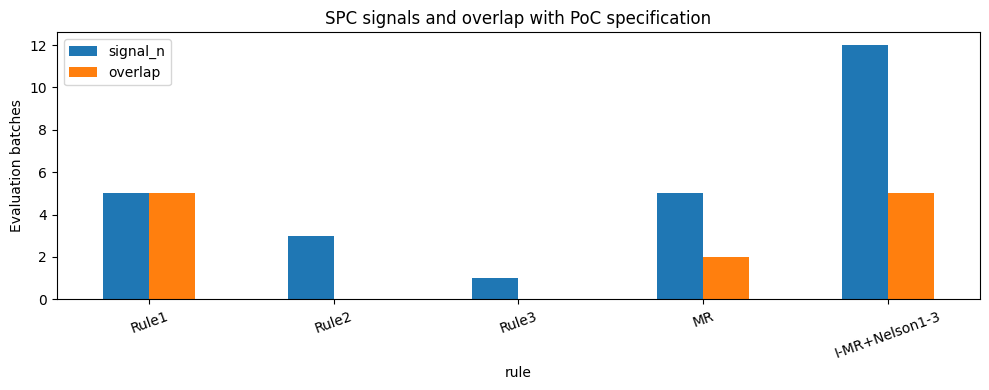

In [5]:
summary=[]
for c,g in signals.groupby('code'):
    h=g[g.phase.eq('test')]; v=h[h.valid_yield]; p=params[c]
    row=dict(code=c,group=p['group'],eval_n=len(h),quality_review_n=int((~h.valid_yield).sum()),spc_eval_n=len(v) if p['imr_ready'] else 0,spec_eval_n=len(v) if p['spec_ready'] else 0)
    for k in R+['spc_any','spc_lower']: row[k]=int(v[k].sum()) if p['imr_ready'] else np.nan
    for k in ['spec_low','spec_high','spec_any','q10_low']: row[k]=int(v[k].sum()) if p['spec_ready'] else np.nan
    row['both']=int((v.spc_any&v.spec_any).sum()) if p['imr_ready'] and p['spec_ready'] else np.nan
    summary.append(row)
summary=pd.DataFrame(summary); summary.to_csv(OUT/'detection_summary.csv',index=False); display(summary)
v=eval_df[eval_df.valid_yield&eval_df.imr_ready&eval_df.spec_ready]
sets={'Rule1':R[:2],'Rule2':R[2:4],'Rule3':R[4:6],'MR':['mr_high'],'I-MR+Nelson1-3':R}
rows=[]
for scope,h in [('ALL_A',v),('ML_focus',v[v.code.isin(FOCUS)])]:
    for name,cols in sets.items():
        flag=h[cols].any(axis=1); q=h.spec_any
        rows.append(dict(scope=scope,rule=name,n=len(h),signal_n=int(flag.sum()),signal_rate=flag.mean(),spec_n=int(q.sum()),overlap=int((flag&q).sum()),spec_only=int((q&~flag).sum()),spc_only=int((flag&~q).sum())))
compare=pd.DataFrame(rows); compare.to_csv(OUT/'rule_comparison.csv',index=False); display(compare.round(4))
fig,ax=plt.subplots(figsize=(10,4)); compare[compare.scope.eq('ALL_A')].set_index('rule')[['signal_n','overlap']].plot.bar(ax=ax,rot=20); ax.set(ylabel='Evaluation batches',title='SPC signals and overlap with PoC specification'); fig.tight_layout(); fig.savefig(OUT/'rule_comparison.png',dpi=150); plt.show(); plt.close(fig)

## 4. 관리한계 및 신호 민감도
같은 평가 배치에 대해 전체 기준 기간, 기준 배치 앞 70%, 뒤 70%를 비교한다. 부분 기준은 유효 배치 최소 20개를 허용하는 탐색적 실험이며 실제 Group A 운영 승인 기준을 낮추는 것이 아니다. 부분 기준의 앞/뒤는 완료 순서를 기준으로 선택한다. 평가 시점 이전의 실제 관측 이력은 동일하게 유지하여 기준값 변화의 영향만 비교한다. 기준 기간의 안정성 및 공정 변화는 별도 담당자 확인이 필요하다.

,code,reference,ref_n,eval_n,ready,cl,lcl,ucl,mr_ucl,lsl,lcl_delta,mr_ucl_delta,spc_n,spec_n,spc_changed_n,spec_changed_n,spc_added,spc_removed
0,1,full,95,0,True,97.6287,94.2479,101.0096,4.1530,96.5,0.0000,0.0000,0,0,0,0,0,0
1,1,early70,67,0,True,97.6034,94.1877,101.0192,4.1959,96.0,-0.0602,0.0429,0,0,0,0,0,0
2,1,late70,67,0,True,97.5332,94.0815,100.9849,4.2401,96.5,-0.1664,0.0871,0,0,0,0,0,0
3,13,full,70,60,True,98.7784,97.5688,99.9880,1.4859,97.5,0.0000,0.0000,2,1,0,0,0,0
4,13,early70,49,60,True,98.9140,97.7352,100.0928,1.4480,98.0,0.1665,-0.0379,7,8,5,7,5,0
5,13,late70,49,60,True,98.6038,97.2751,99.9325,1.6322,97.5,-0.2937,0.1463,1,1,1,0,0,1
6,15,full,40,23,True,98.7137,96.9265,100.5009,2.1954,97.0,0.0000,0.0000,2,2,0,0,0,0
7,15,early70,29,23,True,98.6640,96.6779,100.6501,2.4397,97.0,-0.2486,0.2443,1,2,1,0,0,1
8,15,late70,28,23,True,98.9579,97.4997,100.4162,1.7913,98.5,0.5732,-0.4041,2,5,0,3,0,0
9,17,full,119,88,True,98.6395,96.7349,100.5440,2.3396,97.5,0.0000,0.0000,4,4,0,0,0,0


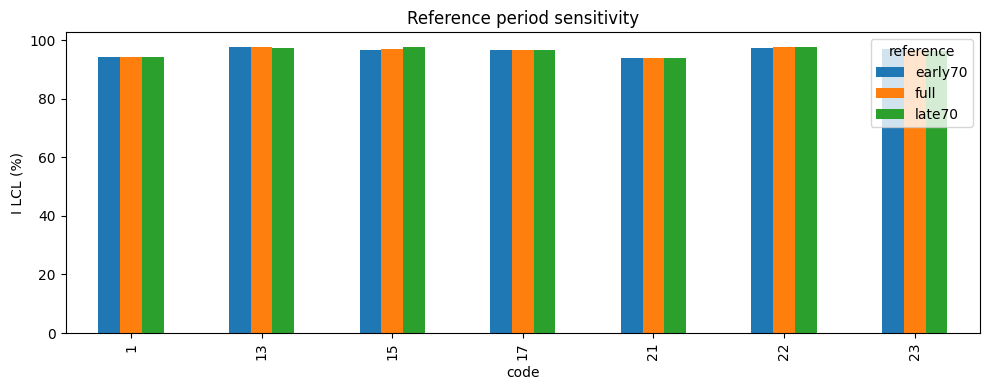

In [6]:
sensitivity=[]
for c,g in df.groupby('code'):
    ref=g[g.phase.eq('train')]; base=params[c]
    if not (base['imr_ready'] and base['spec_ready']): continue
    m=int(np.ceil(len(ref)*.7)); orig=score(g,base); o=orig[orig.phase.eq('test')&orig.valid_yield].reset_index(drop=True)
    for label,r in [('full',ref),('early70',ref.iloc[:m]),('late70',ref.iloc[-m:])]:
        p=get_limits(r,min_spc=20); a=score(g,p); a=a[a.phase.eq('test')&a.valid_yield].reset_index(drop=True)
        assert a[KEY].equals(o[KEY])
        ready=p['imr_ready'] and p['spec_ready']
        sensitivity.append(dict(code=c,reference=label,ref_n=p['valid_ref_n'],eval_n=len(a),ready=ready,cl=p['cl'],lcl=p['lcl'],ucl=p['ucl'],mr_ucl=p['mr_ucl'],lsl=p['lsl'],lcl_delta=p['lcl']-base['lcl'],mr_ucl_delta=p['mr_ucl']-base['mr_ucl'],spc_n=int(a.spc_any.sum()) if ready else np.nan,spec_n=int(a.spec_any.sum()) if ready else np.nan,spc_changed_n=int(a.spc_any.ne(o.spc_any).sum()) if ready else np.nan,spec_changed_n=int(a.spec_any.ne(o.spec_any).sum()) if ready else np.nan,spc_added=int((a.spc_any&~o.spc_any).sum()) if ready else np.nan,spc_removed=int((~a.spc_any&o.spc_any).sum()) if ready else np.nan))
sens=pd.DataFrame(sensitivity,columns=['code','reference','ref_n','eval_n','ready','cl','lcl','ucl','mr_ucl','lsl','lcl_delta','mr_ucl_delta','spc_n','spec_n','spc_changed_n','spec_changed_n','spc_added','spc_removed'])
sens.to_csv(OUT/'reference_sensitivity.csv',index=False); display(sens.round(4))
if len(sens):
    fig,ax=plt.subplots(figsize=(10,4)); sens.pivot(index='code',columns='reference',values='lcl').plot.bar(ax=ax); ax.set(ylabel='I LCL (%)',title='Reference period sensitivity'); fig.tight_layout(); fig.savefig(OUT/'reference_sensitivity.png',dpi=150); plt.show(); plt.close(fig)

## 5. 기존 RCA 사례 확인
789 및 799: 기존 공통 cutoff의 기준으로 평가. 790: 기존 train 소속이므로 별도 생산 시작 이전 완료 배치 기준으로 재계산. 세 사례 모두 이미 선정된 사례로 독립적인 검증 사례가 아니다. 가상 규격 및 관리한계는 기존 RCA와 동일한 값인지 확인하되 차이가 있다면 기록한다.

,0,1,2
code,17,15,23
batch,789,799,790
phase,test,test,train
case_basis,fixed_cutoff_test,fixed_cutoff_test,prior_only_retrospective
ref_n,119,40,111
tbl_yield,87.973,95.739,93.797
q10,97.6046,97.1717,97.684
lsl,97.5,97.0,97.5
usl,100.0,101.0,100.0
z_score,-14.00265,-3.777227,-6.493456


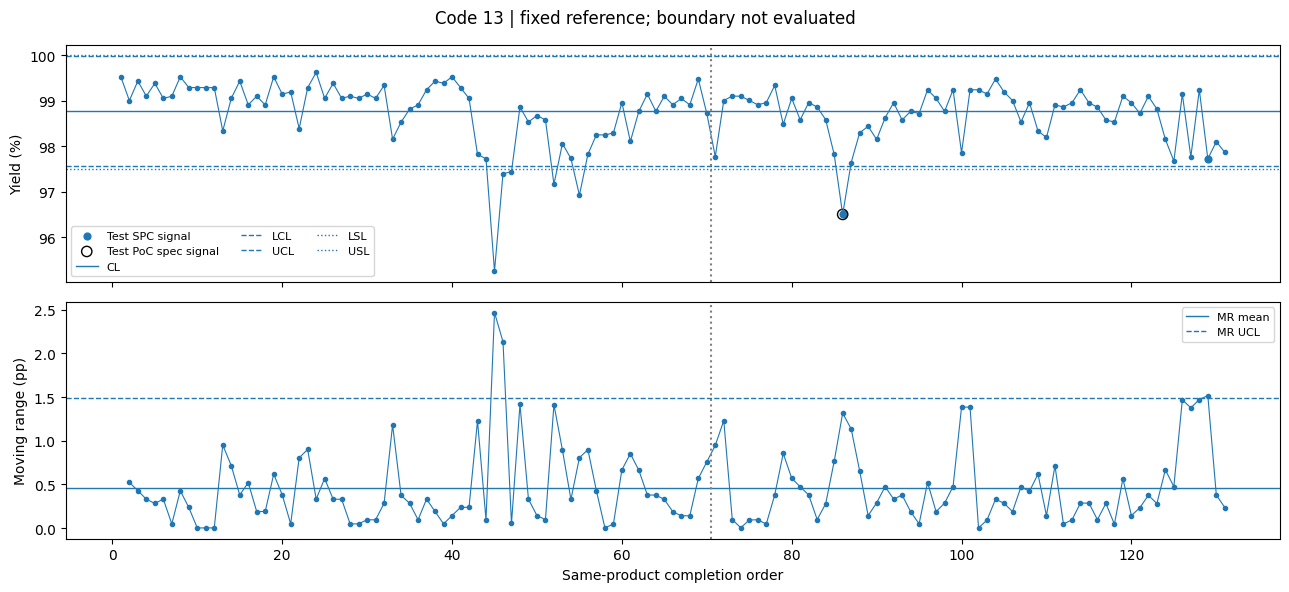

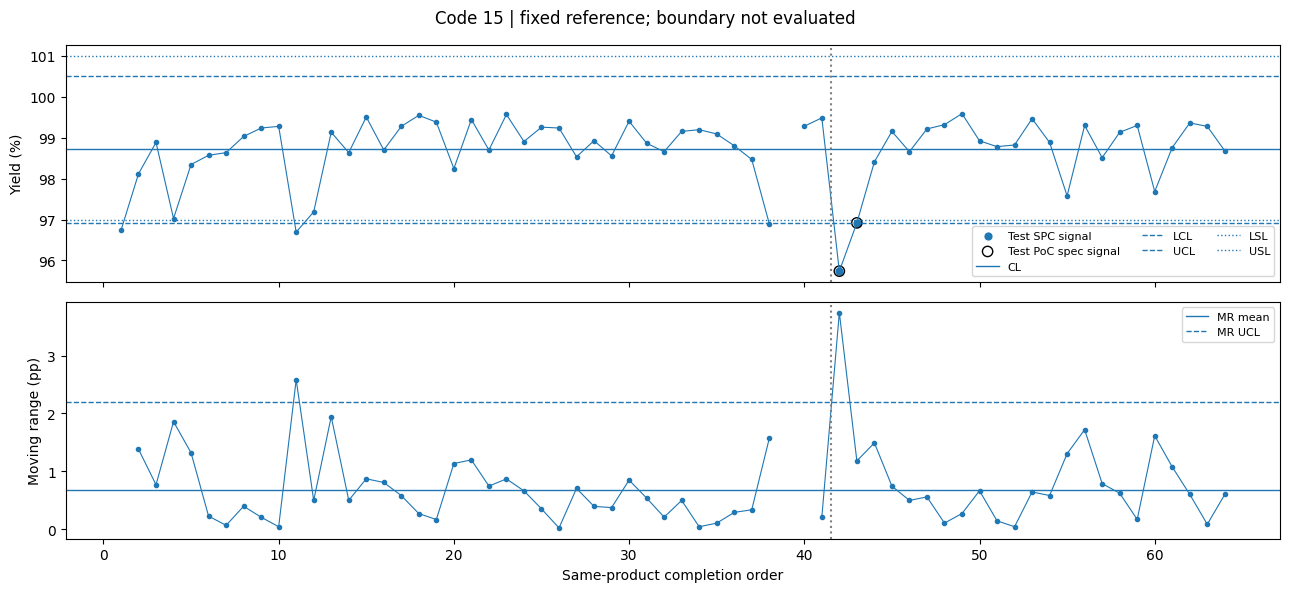

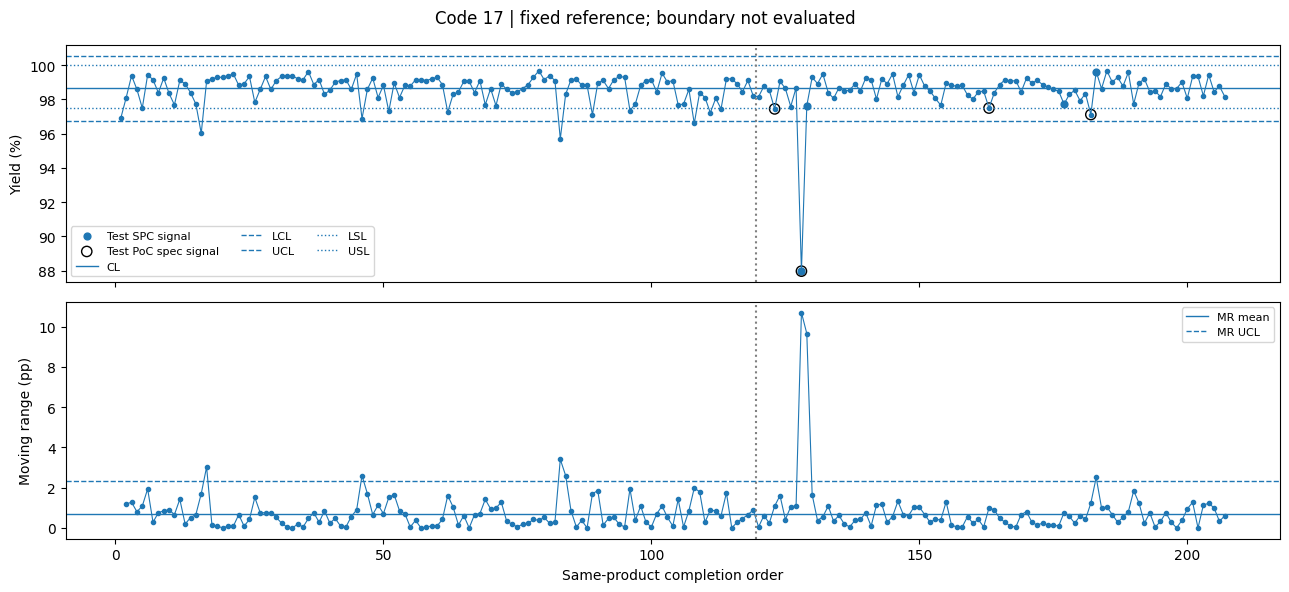

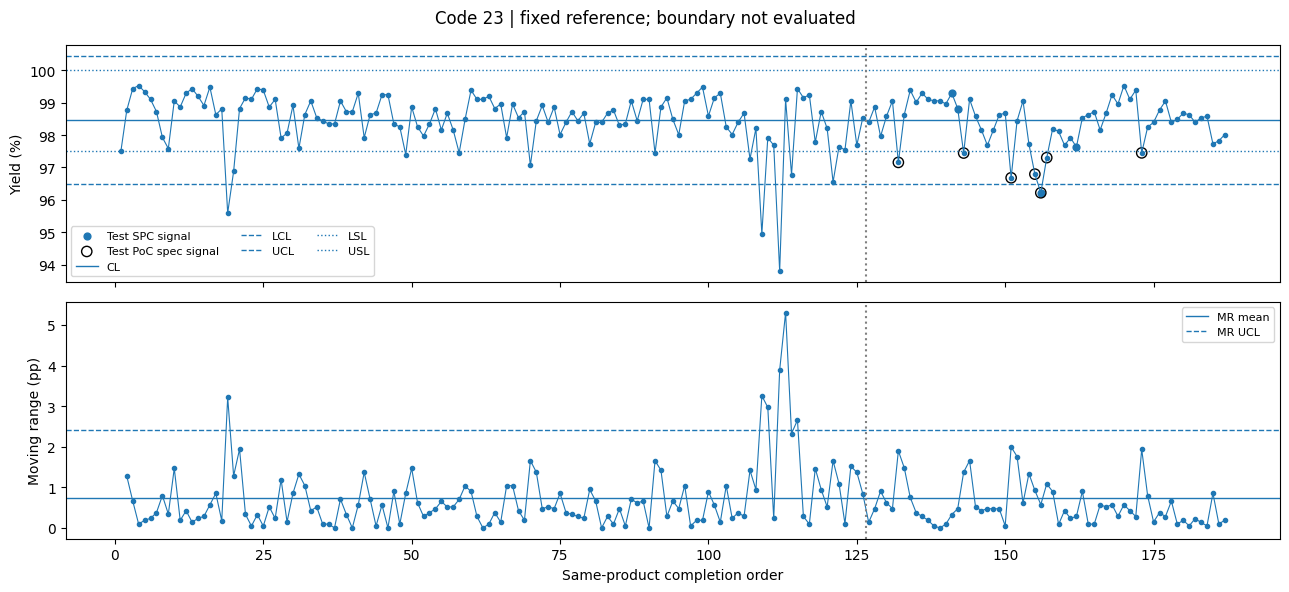

In [7]:
cases=[]
for c,b in [(17,789),(15,799),(23,790)]:
    g=df[df.code.eq(c)]; t=g[g.batch.eq(b)]
    if len(t)!=1: print('Case unavailable:',c,b); continue
    if b==790:
        ref=g[g.end_ts.lt(t.start_ts.iloc[0])]; p=get_limits(ref)
        seq=pd.concat([ref,t]).sort_values(['end_ts','batch']); a=score(seq,p); h=a[a.batch.eq(b)].copy(); h['case_basis']='prior_only_retrospective'; h['ref_n']=p['valid_ref_n']
    else:
        h=signals[signals.code.eq(c)&signals.batch.eq(b)].copy(); h['case_basis']='fixed_cutoff_test'; h['ref_n']=params[c]['valid_ref_n']
    cases.append(h)
cols=KEY+['phase','case_basis','ref_n','tbl_yield','q10','lsl','usl','z_score','cl','lcl','ucl','mr','mr_ucl']+R+['spec_any','spc_any','spec_status','spc_status']
case_result=pd.concat(cases,ignore_index=True)[cols] if cases else pd.DataFrame(columns=cols)
case_result.to_csv(OUT/'rca_case_signals.csv',index=False); display(case_result.T)
for c in [13,15,17,23]:
    if c not in params or not params[c]['imr_ready']: continue
    g=signals[signals.code.eq(c)].reset_index(drop=True); p=params[c]; x=np.arange(1,len(g)+1)
    fig,ax=plt.subplots(2,1,figsize=(13,6),sharex=True)
    a=ax[0]; a.plot(x,g.y,'.-',lw=.8); mask=g.spc_any&g.phase.eq('test'); a.scatter(x[mask],g.loc[mask,'y'],s=24,label='Test SPC signal'); mask=g.spec_any&g.phase.eq('test'); a.scatter(x[mask],g.loc[mask,'y'],facecolors='none',edgecolors='black',s=55,label='Test PoC spec signal')
    for k,style in [('cl','-'),('lcl','--'),('ucl','--'),('lsl',':'),('usl',':')]:
        if np.isfinite(p[k]): a.axhline(p[k],ls=style,lw=1,label=k.upper())
    a.set_ylabel('Yield (%)'); a.legend(ncol=3,fontsize=8)
    ax[1].plot(x,g.mr,'.-',lw=.8); ax[1].axhline(p['mrbar'],lw=1,label='MR mean'); ax[1].axhline(p['mr_ucl'],ls='--',lw=1,label='MR UCL'); ax[1].set(ylabel='Moving range (pp)',xlabel='Same-product completion order'); ax[1].legend(fontsize=8)
    for a in ax:
        a.axvline(int(g.phase.eq('train').sum())+.5,ls=':',color='gray')
    fig.suptitle(f'Code {c} | fixed reference; boundary not evaluated'); fig.tight_layout(); fig.savefig(OUT/f'imr_code_{c}.png',dpi=150); plt.show(); plt.close(fig)

## 6. 운영 설계 및 한계
- 승인 규격이 없으면 GMP OOS 판정 불가. PoC 규격 신호와 통계 신호를 분리한다.
- 그룹 A의 SPC 한계는 기준 데이터 안정성 확인 후 채택. B는 잠정 규격만 표시. C는 판단 보류. 데이터 품질 검토는 별도 상태로 표시.
- 신호가 여러 개 발생해도 배치당 한 개의 조사 요청을 생성하고 fired_rules를 보존한다. Z-score는 심각도 참고값이며 확률 또는 원인 증거가 아니다.
- 수율 공개 시각, 승인 레시피/설비/캠페인 구분, 정상 기준 상태, 공식 일탈 라벨은 미확인. 추세 검정 반복으로 신호율이 증가할 수 있다. 기준을 자동으로 재산정하여 이상을 은폐하지 않는다.
- 이 분석은 원인 확정 또는 제품 출하 판단을 자동화하지 않는다.

In [8]:
metadata=dict(revision='04_v1',python=sys.version,pandas=pd.__version__,numpy=np.__version__,cutoff=str(cut),group_A_min=40,group_B_min=10,sensitivity_min=20,q10=Q,lsl_rounding='floor to 0.5 pp',usl_source=str(SPEC.relative_to(ROOT)),approved_spec_available=False,reference_stability_certified=False,actual_yield_availability_unverified=True,official_deviation_labels=False,hashes={str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in [LAB,AUDIT,SPEC]})
(OUT/'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
assert len(signals)==len(df) and not signals.duplicated(KEY).any()
assert not eval_df.loc[~eval_df.valid_yield,['spc_any','spec_any']].any().any()
print('Completed: 04_statistical_detection_v1 |',OUT)

Completed: 04_statistical_detection_v1 | /Users/park-inki/Desktop/SKALA-yield-model/yield_experiment/results/revision_20261125/04_statistical_detection
